# Spatiotemporal shotgun screen — XGBoost

A reduced-compute **first-stage screen** of nonlinear spatiotemporal ideas that can be added to your current XGBoost **47-term binary BoW** model.

### Stage A: append or replace features

**10 configurations:** existing baseline, age-first comps, property-type quota, both, lagged market indices, multiscale comps, approximate time-adjusted comp, spatial-temporal Fourier/RBF features, nonlinear spline/tensor basis, and the combined feature package. All are fitted on the same sampled historical sale cohort and scored on the same held-out month.

### Stage B: fit residual corrections on earlier out-of-time predictions

**8 configurations:** kNN, local Gaussian kernel, RBF-ridge, additive spline GAM approximation, tensor-spline GAM approximation, ExtraTrees, histogram boosting, and a small Gaussian process. The residual-model targets come from earlier months predicted by base XGBoost models trained only on older sale months. Stage B corrects the **same baseline predictions** made in Stage A.

This is not a full geostatistical GAM, STARIMA, NNGP, DeepKriging or graph-neural implementation. It screens inexpensive representatives from relevant families before we invest in heavier standalone models.

**Crucial limitations:** the sample/trees are intentionally smaller than your full six-month XGBoost benchmark; numbers are **not** expected to reproduce 7.82% MdAPE. The 500-ish homes in the selected October validation fold are reused for ranking variants. Validate only a frozen shortlist on a different historical fold and eventually the full-data confirmation/fixed-origin runs. No results will be written to `logs.md` automatically.

In [8]:
import pandas as pd
from IPython.display import display
from spacetime_shotgun import run_shotgun, SCREEN_FEATURE_VARIANTS
from models.spacetime_screen_residuals import RESIDUAL_VARIANTS

VALIDATION_MONTH = "2025-10"  # must be earlier than December 2025
TRAIN_START = "2023-01-01"
TRAIN_CAP = 10000              # random sample of historical sales
VALIDATION_CAP = 650           # holdout sales, excluded from ALL training
CALIBRATION_CAP = 650          # per earlier calibration month
CALIBRATION_FOLDS = 2         # August and September 2025 by default
SCREEN_TREES = 220            # not the full tuned 700 trees
RESIDUAL_STRENGTH = 0.5
SEED = 42

FEATURES = list(SCREEN_FEATURE_VARIANTS)
RESIDUALS = list(RESIDUAL_VARIANTS)
print("Feature candidates:", FEATURES)
print("Residual candidates:", RESIDUALS)

Feature candidates: ['baseline', 'market', 'multiscale', 'time_adjusted_comp', 'spacetime_rbf', 'spacetime_splines', 'combined', 'comp_age_first', 'comp_type_quota', 'comp_both']
Residual candidates: ['knn', 'local_kernel', 'rbf_ridge', 'spline_gam', 'tensor_gam', 'extra_trees', 'hist_boost', 'small_gp']


In [9]:
scores, predictions, failures = run_shotgun(
    validation_month=VALIDATION_MONTH,
    train_start=TRAIN_START,
    train_cap=TRAIN_CAP,
    validation_cap=VALIDATION_CAP,
    calibration_cap=CALIBRATION_CAP,
    calibration_folds=CALIBRATION_FOLDS,
    screen_trees=SCREEN_TREES,
    seed=SEED,
    features=FEATURES,
    residuals=RESIDUALS,
    residual_strength=RESIDUAL_STRENGTH,
)
display(scores)
if failures:
    print(f"{len(failures)} failed candidates; see outputs/spacetime_shotgun/failures.json.")
    display(pd.DataFrame(failures)[["arm", "variant", "error"]])

Shotgun: 10,000 historical sales; 650 unseen 2025-10 homes; 220 trees per XGBoost
  feature  baseline              MdAPE 11.394% MAPE 13.074% (ΔMdAPE +0.000pp)
  feature  market                MdAPE 10.595% MAPE 13.247% (ΔMdAPE -0.799pp)
  feature  multiscale            MdAPE 10.865% MAPE 13.163% (ΔMdAPE -0.529pp)
  feature  time_adjusted_comp    MdAPE 11.174% MAPE 13.161% (ΔMdAPE -0.221pp)
  feature  spacetime_rbf         MdAPE 11.031% MAPE 13.397% (ΔMdAPE -0.363pp)
  feature  spacetime_splines     MdAPE 10.871% MAPE 12.831% (ΔMdAPE -0.524pp)
  feature  combined              MdAPE 10.171% MAPE 13.115% (ΔMdAPE -1.224pp)
  feature  comp_age_first        MdAPE 11.102% MAPE 13.027% (ΔMdAPE -0.293pp)
  feature  comp_type_quota       MdAPE 11.104% MAPE 13.272% (ΔMdAPE -0.291pp)
  feature  comp_both             MdAPE 11.286% MAPE 13.175% (ΔMdAPE -0.109pp)
  Calibration 2025-08: 10,000 earlier sales, 650 OOT errors
  Calibration 2025-09: 10,000 earlier sales, 650 OOT errors
  residual knn    

,homes,mape,mdape,median_signed,arm,variant,delta_mdape_pp,delta_mape_pp
6,650,13.115005,10.170555,0.962630,feature,combined,-1.223921,0.040741
1,650,13.246723,10.595295,0.867426,feature,market,-0.799181,0.172460
10,650,13.000553,10.805515,0.663092,residual,knn,-0.588962,-0.073711
16,650,12.998167,10.861224,0.881887,residual,hist_boost,-0.533252,-0.076096
2,650,13.163312,10.865349,1.920242,feature,multiscale,-0.529128,0.089048
5,650,12.830504,10.870732,0.553561,feature,spacetime_splines,-0.523744,-0.243760
4,650,13.396770,11.031454,1.448840,feature,spacetime_rbf,-0.363022,0.322506
12,650,12.966440,11.046205,0.628535,residual,rbf_ridge,-0.348271,-0.107823
14,650,12.989228,11.046502,0.811455,residual,tensor_gam,-0.347975,-0.085035
13,650,12.977714,11.095606,0.835856,residual,spline_gam,-0.298871,-0.096550


,homes,mape,mdape,median_signed,arm,variant,delta_mdape_pp,delta_mape_pp
8,650,12.488057,9.986896,0.142613,feature,comp_type_quota,-0.495399,-0.212629
9,650,12.488057,9.986896,0.142613,feature,comp_both,-0.495399,-0.212629
0,650,12.700686,10.482295,0.166483,feature,baseline,0.000000,0.000000
7,650,12.700686,10.482295,0.166483,feature,comp_age_first,0.000000,0.000000
1,650,12.881926,10.488490,-0.077106,feature,market,0.006195,0.181240
2,650,12.867510,10.529488,1.054665,feature,multiscale,0.047194,0.166824
6,650,12.704544,10.630527,0.560060,feature,combined,0.148232,0.003858
3,650,12.838659,10.689522,-0.216489,feature,time_adjusted_comp,0.207227,0.137973
5,650,13.047621,10.811984,-0.812053,feature,spacetime_splines,0.329690,0.346935
4,650,13.060216,10.961533,-0.113286,feature,spacetime_rbf,0.479238,0.359530


mdape            mape         delta_mdape_pp        delta_mape_pp  \
             min  median     min  median            min median           min   
arm                                                                            
feature    9.987  10.509  12.488  12.772         -0.495  0.027        -0.213   
residual  10.204  10.381  12.622  12.644         -0.278 -0.101        -0.079   

                 
         median  
arm              
feature   0.071  
residual -0.057

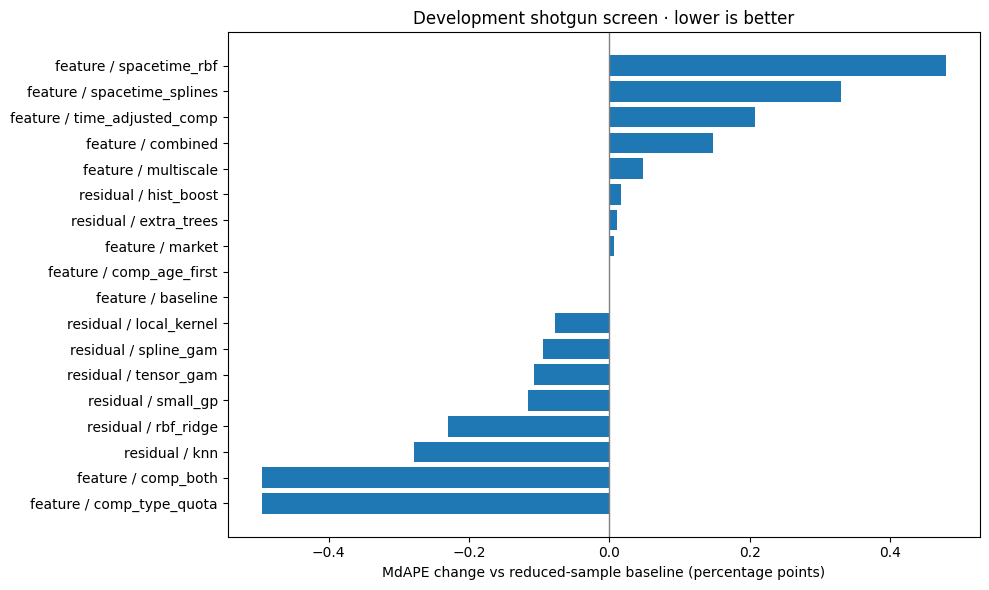

In [5]:
# Feature and residual experiments must be compared separately to baseline.
display(scores.sort_values(["arm", "mdape"]))
display(
    scores.groupby("arm")[["mdape", "mape", "delta_mdape_pp", "delta_mape_pp"]]
    .agg(["min", "median"]).round(3)
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
p = scores.sort_values("delta_mdape_pp")
ax.barh(p["arm"] + " / " + p["variant"], p["delta_mdape_pp"])
ax.axvline(0, linewidth=1, color="gray")
ax.set_xlabel("MdAPE change vs reduced-sample baseline (percentage points)")
ax.set_title("Development shotgun screen · lower is better")
fig.tight_layout()
plt.show()

In [6]:
# Check whether proposed fixes help difficult property categories rather
# than only changing aggregate error. This is an optional diagnostic; the
# ranking itself is based on held-out prices from one month.
import data
sales = data.load("listings")
sold_month = pd.to_datetime(sales["date_sold"]).dt.to_period("M")
names = sales.loc[sold_month == pd.Period(VALIDATION_MONTH), [
    "ml_num", "house_type_name"
]]
annotated = predictions.merge(names, on="ml_num", how="left", validate="many_to_one")
subgroups = (
    annotated.groupby(["arm", "variant", "house_type_name"])
    .agg(n=("ml_num", "size"), mdape=("abs_pct_error", "median"))
    .query("n >= 10")
    .sort_values(["house_type_name", "mdape"])
)
display(subgroups.head(40))
print("Full result CSV: outputs/spacetime_shotgun/predictions.csv")

n      mdape
arm      variant            house_type_name                
feature  multiscale         Condo Apt        290   9.649046
residual tensor_gam         Condo Apt        290   9.856606
         extra_trees        Condo Apt        290   9.885602
feature  baseline           Condo Apt        290   9.912425
         comp_age_first     Condo Apt        290   9.912425
residual rbf_ridge          Condo Apt        290   9.929440
         spline_gam         Condo Apt        290   9.980892
feature  spacetime_splines  Condo Apt        290  10.024904
residual knn                Condo Apt        290  10.061366
feature  comp_both          Condo Apt        290  10.109944
         comp_type_quota    Condo Apt        290  10.109944
residual local_kernel       Condo Apt        290  10.117777
         small_gp           Condo Apt        290  10.153834
         hist_boost         Condo Apt        290  10.175840
feature  market             Condo Apt        290  10.176382
         time_adjusted_comp Condo Apt        290  10.185250
         combined           Condo Apt        290  10.240703
         spacetime_rbf      Condo Apt        290  10.548261
residual small_gp           Condo Townhouse   47   7.650315
         extra_trees        Condo Townhouse   47   7.727639
feature  comp_both          Condo Townhouse   47   7.768151
         comp_type_quota    Condo Townhouse   47   7.768151
residual hist_boost         Condo Townhouse   47   7.901657
feature  baseline           Condo Townhouse   47   8.025815
         comp_age_first     Condo Townhouse   47   8.025815
         market             Condo Townhouse   47   8.040465
residual spline_gam         Condo Townhouse   47   8.132384
         rbf_ridge          Condo Townhouse   47   8.191669
feature  time_adjusted_comp Condo Townhouse   47   8.232309
residual local_kernel       Condo Townhouse   47   8.486924
         tensor_gam         Condo Townhouse   47   8.524789
         knn                Condo Townhouse   47   8.924534
feature  combined           Condo Townhouse   47   9.231921
         multiscale         Condo Townhouse   47   9.234886
         spacetime_rbf      Condo Townhouse   47   9.805106
         spacetime_splines  Condo Townhouse   47  10.736517
         comp_both          Detached         207   9.995633
         comp_type_quota    Detached         207   9.995633
         market             Detached         207  10.518968
residual knn                Detached         207  10.528568

Full result CSV: outputs/spacetime_shotgun/predictions.csv


## Second-stage research after the screen

Once a small number of configurations survive on October 2025, switch `VALIDATION_MONTH` to another **earlier** month, keeping settings fixed. Check stability, errors by house type, and fixed-origin issues.

A later **standalone/residual model comparison** can then evaluate more expensive nonlinear methods (geographically weighted random forest, DeepKriging, a genuine spatiotemporal GAM/tensor smoother, scalable NNGP, spatiotemporal GNN, and neural autoregressive regional models). Those methods need their own honest, comparable training protocol; many also require aggregating transactions into regional monthly series. They have **not** been implemented as part of this quick screen.

### Installation and test

```powershell
git pull origin main
uv sync
uv run python -m pytest tests/test_spacetime_shotgun.py -q
uv run jupyter lab
```

You can also run the screen without Jupyter:

```powershell
uv run python spacetime_shotgun.py --validation-month 2025-10
```

To reduce initial compute further, set `TRAIN_CAP=5000`, `VALIDATION_CAP=250`, `SCREEN_TREES=100`, and choose a subset of `FEATURES` and `RESIDUALS`. Do not infer small score changes from these very small samples.